# code_032 · Baselines and experimental questions

**Book:** section 7.1. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_07_GUIDE.md), [execution evidence](../CHAPTER_07_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_032). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=732;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 732


<a id="claim"></a>
## A claim that could fail

Predict measured midspan deflection in mm for new independent, idealized simply supported beams under a central point load. Inputs available beforehand: force P N, span L m and second moment I m⁴; E=200e9 Pa is known and fixed. The nominal small-deflection Euler–Bernoulli reference is 1000*P*L³/(48*E*I) mm. Real support conditions, shear effects and material departures are not validated here.

Construct y=.12+nominal+.2*nominal*(L/3-1)+Gaussian noise sd .04 mm. This deliberately favors an available residual representation; it is not measured beam evidence. Allocate 300/100/100 independent beams before fitting. Predeclare: does the learned residual correction lower MAE versus the nominal calculation by at least .03 mm on this generator? This illustrative practical threshold is not a real engineering acceptance limit or a significance test.

Baselines: training-target mean; a fixed reference-compliance heuristic using L=3 m,I=1e-5 m⁴; the nominal solver using each beam's P,L,I; ordinary linear regression in normalized raw inputs; a learned residual correction added to the nominal calculation. Eligible ridge alphas [.01,1,100] are the same three development candidates for the two learned rules. Final outcomes never choose a setting.


In [2]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
E=200e9;N=500;P=rng.uniform(5000,20000,N);L=rng.uniform(2,4,N);I=rng.uniform(6e-6,1.4e-5,N)
def nominal(P,L,I):return 1000*P*L**3/(48*E*I)
assert np.isclose(nominal(10000.,3.,1e-5),2.8125)
reference=nominal(P,L,I);y=.12+reference+.2*reference*(L/3-1)+rng.normal(0,.04,N)
tr=np.arange(300);dv=np.arange(300,400);te=np.arange(400,500)
X=np.column_stack([P/1e4,L/3,I/1e-5]);residual_X=np.column_stack([reference,reference*(L/3-1)])
assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
assert np.all(P>0) and np.all(I>0) and np.all(reference>0)
constant=np.full(N,y[tr].mean());heuristic=nominal(P,np.full(N,3.),np.full(N,1e-5))
RESULTS['reference_check_mm']=float(nominal(10000.,3.,1e-5));RESULTS['practical_MAE_gain_threshold_mm']=.03


<a id="development"></a>
## Match what the comparison is allowed to use

Every learned candidate sees the same training/development members. The residual rule has access to a mechanistic feature also available to all baselines, but uses a different representation; any gain belongs to that complete procedure rather than a universal estimator advantage. Fit scalers on training only. Select each family's alpha by development MAE with the first candidate breaking exact ties. The fixed solver and heuristic do not fit labels.


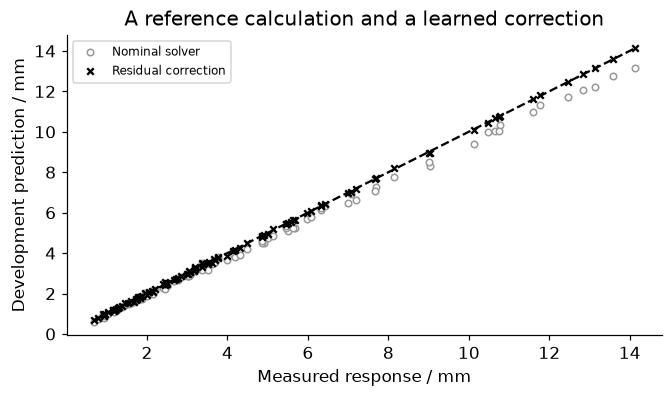

In [3]:
alphas=[.01,1.,100.];chosen={};development_scores={}
for name,features,target,offset in [('linear',X,y,np.zeros(N)),('residual',residual_X,y-reference,reference)]:
 candidates=[make_pipeline(StandardScaler(),Ridge(alpha=a)).fit(features[tr],target[tr]) for a in alphas]
 scores=[float(np.mean(abs(m.predict(features[dv])+offset[dv]-y[dv]))) for m in candidates]
 index=int(np.argmin(scores));chosen[name]=candidates[index];development_scores[name]=scores
 assert np.allclose(candidates[index][0].mean_,features[tr].mean(0))
 RESULTS[name+'_selected_alpha']=alphas[index]
assert len(development_scores['linear'])==len(development_scores['residual'])==3
fig,ax=plt.subplots(figsize=(6,3.5));ax.scatter(y[dv],reference[dv],s=18,facecolors='white',edgecolors='.6',label='Nominal solver');ax.scatter(y[dv],chosen['residual'].predict(residual_X[dv])+reference[dv],s=18,marker='x',color='black',label='Residual correction')
bounds=[float(y[dv].min()),float(y[dv].max())];ax.plot(bounds,bounds,'k--');ax.set(xlabel='Measured response / mm',ylabel='Development prediction / mm',title='A reference calculation and a learned correction');ax.legend(fontsize=8);plt.show()
RESULTS['development_MAE_candidates_mm']=development_scores


<a id="final"></a>
## Freeze rules and compare paired final losses

Open final targets once for every predeclared rule, with no final winner-based refit. Paired per-beam error differences are meaningful because each rule predicts the same member. A mean gain does not show all subgroups improve and does not include field-model uncertainty. RMSE and MAE retain mm units.


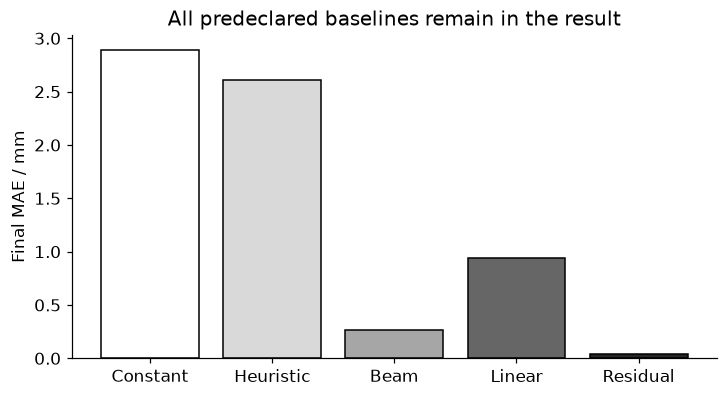

{'reference_check_mm': 2.8124999999999996, 'practical_MAE_gain_threshold_mm': 0.03, 'linear_selected_alpha': 1.0, 'residual_selected_alpha': 0.01, 'development_MAE_candidates_mm': {'linear': [0.9568633457648077, 0.95558599207781, 1.0079489169488536], 'residual': [0.03354492303052639, 0.033672512101506714, 0.05559861666594625]}, 'final_MAE_mm': {'constant': 2.8894330809500484, 'heuristic': 2.609262725028362, 'beam_solver': 0.26178568281530823, 'linear': 0.9369126491670905, 'residual': 0.037383545612102435}, 'final_RMSE_mm': {'constant': 3.8070198065680114, 'heuristic': 3.613950032550831, 'beam_solver': 0.3586632715473802, 'linear': 1.3499587770884562, 'residual': 0.04415430340598707}, 'paired_mean_MAE_gain_mm': 0.2244021372032058, 'practical_threshold_met': True}


In [4]:
predictions={'constant':constant[te],'heuristic':heuristic[te],'beam_solver':reference[te],
'linear':chosen['linear'].predict(X[te]),'residual':reference[te]+chosen['residual'].predict(residual_X[te])}
mae={k:float(np.mean(abs(pred-y[te]))) for k,pred in predictions.items()};rmse={k:float(np.sqrt(np.mean((pred-y[te])**2))) for k,pred in predictions.items()}
gain=np.abs(predictions['beam_solver']-y[te])-np.abs(predictions['residual']-y[te])
assert all(v.shape==(100,) for v in predictions.values()) and np.isfinite(list(mae.values())).all()
assert np.isclose(gain.mean(),mae['beam_solver']-mae['residual'])
fig,ax=plt.subplots(figsize=(6.5,3.5));ax.bar(np.arange(5),list(mae.values()),color=['white','.85','.65','.4','.15'],edgecolor='black');ax.set(xticks=np.arange(5),xticklabels=['Constant','Heuristic','Beam','Linear','Residual'],ylabel='Final MAE / mm',title='All predeclared baselines remain in the result');plt.show()
RESULTS.update({'final_MAE_mm':mae,'final_RMSE_mm':rmse,'paired_mean_MAE_gain_mm':float(gain.mean()),'practical_threshold_met':bool(gain.mean()>=.03)});print(RESULTS)


<a id="exercises"></a>
## Exercises and hints

1. Remove the constructed correction from the generator. Keep all failed-to-improve results rather than searching a flattering seed.
2. Change the physical supports or load position. Explain why the same 48EI formula is no longer the right reference.
3. Add an equally budgeted purely data-driven nonlinear baseline using development data; reserve fresh final members.
4. Define subgroup and acquisition-cost criteria before opening a new final set.

**Hints:** a claim needs target cases, information access, comparator, metric and a criterion that could reject it. A physics residual fit has a favorable synthetic representation here; it is not a field-validity demonstration. Check N, m, Pa, m⁴ and mm conversions before interpreting errors. The book derives the center-load relation under its stated ideal assumptions.


In [5]:
summary={'example_id':'code_032','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['falsifiable improvement claim', 'constant heuristic mechanistic and simple learned baselines', 'unit-checked beam calculation', 'development-only equal-candidate tuning', 'paired final errors and practical threshold'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["falsifiable improvement claim", "constant heuristic mechanistic and simple learned baselines", "unit-checked beam calculation", "development-only equal-candidate tuning", "paired final errors and practical threshold"], "elapsed_seconds": 0.378, "example_id": "code_032", "hardware": "Darwin arm64 CPU", "results": {"development_MAE_candidates_mm": {"linear": [0.9568633457648077, 0.95558599207781, 1.0079489169488536], "residual": [0.03354492303052639, 0.033672512101506714, 0.05559861666594625]}, "final_MAE_mm": {"beam_solver": 0.26178568281530823, "constant": 2.8894330809500484, "heuristic": 2.609262725028362, "linear": 0.9369126491670905, "residual": 0.037383545612102435}, "final_RMSE_mm": {"beam_solver": 0.3586632715473802, "constant": 3.8070198065680114, "heuristic": 3.613950032550831, "linear": 1.3499587770884562, "residual": 0.04415430340598707}, "linear_selected_alpha": 1.0, "paired_mean_MAE_gain_mm": 0.2244021372032058, "practical_